# Supplementary checks

This notebook reproduces the numbers that the paper quotes in the text but does not plot. Most of them answer referee comments. It uses the model of `paper_figures.ipynb`, unchanged: the same Hamiltonians, reset, Doppler-cooled initial state ($\bar n\simeq10.5$, $N=100$) and $R=80$ cycles.

| section | result | where in the paper |
|---|---|---|
| 1 | dephasing test: the calibration gain is a multi-cycle coherent effect; timing-jitter tolerance | Sec. III B |
| 2 | an end kick $D(i\eta/2)$ only partly removes the half-recoil offset | Sec. II B (pulse sequence) |
| 3 | spread of $\Omega$ from the thermal motion of a radial mode (tilted 729-nm beam) | not in the paper (reply to the referees) |
| 4 | magnetic field perpendicular to the trap axis: the 393-nm emission pattern | not in the paper (reply to the referees) |
| 5 | stroboscopic resonance of the cycle period with the trap period | Sec. III B; Figs. 5(A), 7(B) |

All runs are serial and uncached. The notebook takes about 2–3 hours on a laptop; sections 1 and 3 are the longest.

**Loading the model.** The cell below executes every code cell of `paper_figures.ipynb` above the marker `# ==== FIGURES`. That defines the parameters, the pulses, `reset_map`, `iterate`, `sim`, `calibrate_many` and the cache, and reads the cached calibrations without recomputing them.

In [1]:
import json
import os
import time

os.environ["NPROC"] = "1"            # serial; keeps numpy multithreaded
os.environ.pop("SMOKE_TEST", None)

_cells = json.load(open("paper_figures.ipynb", encoding="utf-8"))["cells"]
_src = []
for _c in _cells:
    if _c["cell_type"] != "code":
        continue
    _s = "".join(_c["source"])
    if _s.startswith("# ==== FIGURES"):
        break
    _src.append(_s)
exec(compile("\n\n".join(_src), "paper_figures.ipynb", "exec"))

from qutip import displace
from scipy.special import eval_laguerre

T0 = time.time()


def log(*a):
    print(f"[{time.time() - T0:7.1f}s]", *a)

Initial state: kT = 11 nu, nbar = 10.508, N = 100, weight above N = 1.1e-04, R = 80 cycles; 1 worker processes


40Ca+ at nu = 2 pi x 1 MHz: eta(729 nm, axial) = 0.0969, eta(393 nm) = 0.1796, 854-nm kick = 0.854 eta


### Calibrated timings

These are the calibrated pulse lengths and delays used below. They are read from the cache, where `paper_figures.ipynb` put them: Fig. 5 for the reference model and the $^{40}$Ca$^+$ section (Additional figure S3) for $^{40}$Ca$^+$. Each entry is $(D, f, t_d)$.

In [2]:
TWO_PI = 2 * np.pi
for _mdl, _oy in (("Ca_Oy2", 2.0), ("Ca_Oy1", 1.0)):
    MODELS[_mdl] = dict(Oy=_oy, **CA_RESET)
_cal_ref = calibrate_many([0.05], "ref", "ref")[_r(0.05)]["joint"]
_cal_ca = calibrate_many(ETA_IMPL, "Ca_Oy2", "Ca_Oy2")
ETA_AX = round(float(ETA_CA_AXIAL), 4)                       # 0.0969: 729 nm along the trap axis
CAL = {("ref", 0.05): _cal_ref[1:],
       ("Ca_Oy2", 0.05): _cal_ca[_r(0.05)]["joint"][1:],
       ("Ca_Oy2", ETA_AX): _cal_ca[_r(ETA_AX)]["joint"][1:]}
for k, (f, d) in CAL.items():
    print(f"{k[0]:7s} eta={k[1]:<7g}: f = {f:.5f} (lengthening {(f - 1) * tau_of(k[1]):+.3f}/nu), delay {d:.3f}/nu")


def run(eta, f=1.0, delay=0.0, dOm=0.0, model=None, sigma=0.0, full=False):
    # iterate() of paper_figures.ipynb plus a motional phase jitter of rms sigma (rad) after every cycle:
    # coherences rho_mn are multiplied by exp(-sigma^2 (m-n)^2 / 2); sigma = inf removes them.
    U = U_new(eta, f=f, dOm=dOm, model=model)
    Ud = U.conj().T
    reset = reset_map(eta, model)
    rho = np.zeros((2 * N, 2 * N), dtype=complex)
    rho[N:, N:] = np.diag(P0)
    rot = np.tile(np.exp(-1j * DN * delay), (2, 2)) if delay else 1.0
    dph = 1.0
    if sigma:
        dph = np.tile(np.eye(N) if np.isinf(sigma) else np.exp(-0.5 * sigma ** 2 * DN ** 2), (2, 2))
    for _ in range(R):
        rho = reset(U @ rho @ Ud) * rot * dph
    d = np.real(np.diag(rho)); p = d[:N] + d[N:]
    return (tdist(p, PID), rho[:N, :N] + rho[N:, N:]) if full else tdist(p, PID)

ref     eta=0.05   : f = 1.00200 (lengthening +0.251/nu), delay 0.100/nu


Ca_Oy2  eta=0.05   : f = 0.99250 (lengthening -0.942/nu), delay 4.712/nu


Ca_Oy2  eta=0.0969 : f = 0.99225 (lengthening -0.503/nu), delay 5.298/nu


## 1. Dephasing test: the calibration gain is a multi-cycle coherent effect

**Method.** After every cycle the motional coherences are multiplied by $e^{-\sigma^2(m-n)^2/2}$. This is a random motional phase of rms $\sigma$ per cycle, as produced by timing jitter. The limit $\sigma=\infty$ removes all coherences while leaving the populations untouched; it is equivalent to an inter-cycle delay that is random in every cycle.

**Expected result** (Sec. III B).
- **Full dephasing.**
  - At $\eta=0.05$ the calibrated error rises from $0.025$ to $0.065$ and the nominal error falls from $0.079$ to $0.061$, so the calibration gain disappears.
  - At $\eta=0.055$–$0.075$ the nominal error rises from $0.065$–$0.11$ to $0.19$–$0.37$.
- **Jitter of $0.1$ rad rms** ($16$ ns at $\nu=2\pi\times1$ MHz) changes every error by less than $0.003$.

In [3]:
f0, d0 = CAL[("ref", 0.05)]
for sig in (0.0, 0.03, 0.1, 0.2, 0.3, np.inf):
    log(f"eta=0.05 sigma={sig}: nominal {run(0.05, sigma=sig):.4f}  calibrated {run(0.05, f0, d0, sigma=sig):.4f}")
best = min((run(0.05, f=1 + 0.05 * fr, sigma=np.inf), fr) for fr in CAL_F_REL)
log(f"eta=0.05 full dephasing, best f = 1 + {best[1]:.2f} eta: {best[0]:.4f}")
for e in (0.055, 0.06, 0.065, 0.07, 0.075):
    log(f"eta={e}: nominal coherent {run(e):.4f}, sigma=0.1 {run(e, sigma=0.1):.4f}, "
        f"full dephasing {run(e, sigma=np.inf):.4f}")

[  106.1s] eta=0.05 sigma=0.0: nominal 0.0789  calibrated 0.0245


[  232.3s] eta=0.05 sigma=0.03: nominal 0.0787  calibrated 0.0246


[  347.5s] eta=0.05 sigma=0.1: nominal 0.0762  calibrated 0.0255


[  464.4s] eta=0.05 sigma=0.2: nominal 0.0696  calibrated 0.0285


[  590.3s] eta=0.05 sigma=0.3: nominal 0.0628  calibrated 0.0331


[  712.1s] eta=0.05 sigma=inf: nominal 0.0606  calibrated 0.0648


... (2 outputs left out)

[ 1656.8s] eta=0.06: nominal coherent 0.0746, sigma=0.1 0.0765, full dephasing 0.2977


[ 1687.7s] eta=0.065: nominal coherent 0.0649, sigma=0.1 0.0674, full dephasing 0.3370


[ 1718.2s] eta=0.07: nominal coherent 0.1149, sigma=0.1 0.1165, full dephasing 0.3200


[ 1750.0s] eta=0.075: nominal coherent 0.1081, sigma=0.1 0.1106, full dephasing 0.3709


## 2. The half-recoil offset and an end kick

**Why there is an offset.** Without the RF kicks of the original proposal, the dark states of the cycle are the displaced Fock states $D(-i\eta/2)|n_0m^2\rangle$, so the sequence prepares the trapped mixture displaced by half a photon recoil. For the ideal mixture this offset costs $\simeq\eta^2(2\langle n\rangle+1)/4$ in trace distance.

**What the end kick does.** In the prepared state the displacement is only partly coherent: $\langle n+1|\rho|n\rangle$ at the trap levels is a fraction of the value for displaced Fock states. A momentum kick $D(i\eta/2)$ at the end of the preparation therefore removes only part of the offset.

**Expected result** (calibrated sequence, $\eta=0.05$).
- The end kick lowers the error from $0.025$ to $0.021$, and the best kick of any size and phase to $0.020$.
- At the trap levels $n\ge4$ the coherences are $70$–$80\%$ of those of displaced Fock states.

The second cell splits the change in trace distance into trap and off-trap levels. It also shows what an exact "undisplacement" of the populations would give.

In [4]:
eta = 0.05
for lab, (f, d) in (("nominal", (1.0, 0.0)), ("calibrated", CAL[("ref", eta)])):
    td, rho = run(eta, f, d, full=True)
    ea = np.trace(_a @ rho)
    rs, ths = np.linspace(0, 0.06, 25), np.linspace(0, TWO_PI, 48, endpoint=False)
    best = (td, 0.0, 0.0)
    for r in rs[1:]:
        for th in ths:
            Dm = displace(N, r * np.exp(1j * th)).full()
            v = tdist(np.real(np.diag(Dm @ rho @ Dm.conj().T)), PID)
            if v < best[0]:
                best = (v, r, th)
    Dk = displace(N, 1j * eta / 2).full()
    v_kick = tdist(np.real(np.diag(Dk @ rho @ Dk.conj().T)), PID)
    log(f"{lab}: TD {td:.4f}; <a> = {ea.real:+.4f}{ea.imag:+.4f}i (-i eta/2 = -{eta / 2:.3f}i); "
        f"kick D(i eta/2): {v_kick:.4f}; best kick |beta|={best[1]:.4f}, arg={best[2]:.2f}: {best[0]:.4f}")
    for m in range(1, 6):
        k = m * m
        disp = -1j * eta / 2 * np.sqrt(k + 1) * (rho[k, k].real - rho[k + 1, k + 1].real)
        log(f"   rho[{k}+1,{k}] = {rho[k + 1, k]:.5f}  vs mixture of displaced Fock states {disp:.5f} "
            f"(ratio {abs(rho[k + 1, k]) / abs(disp):.2f})")
Dm = displace(N, -1j * eta / 2).full()
pid_disp = np.real(np.diag(Dm @ np.diag(PID) @ Dm.conj().T))
log(f"ideal trapped mixture displaced by half a recoil: TD {tdist(pid_disp, PID):.4f} "
    f"(eta^2(2<n>+1)/4 = {eta ** 2 * (2 * np.dot(np.arange(N), PID) + 1) / 4:.4f})")

[ 2011.8s] nominal: TD 0.0789; <a> = +0.0064-0.0109i (-i eta/2 = -0.025i); kick D(i eta/2): 0.0770; best kick |beta|=0.0200, arg=1.05: 0.0755


[ 2011.8s]    rho[1+1,1] = -0.00025-0.00793j  vs mixture of displaced Fock states 0.00000-0.00795j (ratio 1.00)


[ 2011.8s]    rho[4+1,4] = -0.00148-0.01400j  vs mixture of displaced Fock states 0.00000-0.01426j (ratio 0.99)


[ 2011.8s]    rho[9+1,9] = -0.00311-0.01393j  vs mixture of displaced Fock states 0.00000-0.01541j (ratio 0.93)


[ 2011.8s]    rho[16+1,16] = -0.00257-0.00728j  vs mixture of displaced Fock states 0.00000-0.01019j (ratio 0.76)


[ 2011.8s]    rho[25+1,25] = -0.00059-0.00160j  vs mixture of displaced Fock states 0.00000-0.00385j (ratio 0.44)


... (3 outputs left out)

[ 2269.9s]    rho[9+1,9] = -0.00227-0.01156j  vs mixture of displaced Fock states 0.00000-0.01591j (ratio 0.74)


[ 2269.9s]    rho[16+1,16] = -0.00134-0.00905j  vs mixture of displaced Fock states 0.00000-0.01285j (ratio 0.71)


[ 2269.9s]    rho[25+1,25] = -0.00063-0.00534j  vs mixture of displaced Fock states 0.00000-0.00763j (ratio 0.70)


[ 2270.1s] ideal trapped mixture displaced by half a recoil: TD 0.0109 (eta^2(2<n>+1)/4 = 0.0111)


In [5]:
traps = np.array([m * m for m in range(10) if m * m < N])
is_trap = np.zeros(N, bool); is_trap[traps] = True
off = pid_disp - PID                                    # the half-recoil offset pattern
for lab, (f, d) in (("nominal", (1.0, 0.0)), ("calibrated", CAL[("ref", eta)])):
    td, p, rho = sim(dict(eta=eta, f=f, delay=d, out="rho"))
    Dk = displace(N, 1j * eta / 2).full()
    pk = np.real(np.diag(Dk @ rho @ Dk.conj().T))
    e0, e1 = np.abs(p - PID), np.abs(pk - PID)
    print(f"{lab}: TD {td:.4f} -> after the kick {tdist(pk, PID):.4f}")
    print(f"   change of the trap-level part   {0.5 * (e1 - e0)[is_trap].sum():+.4f}")
    print(f"   change of the off-trap part     {0.5 * (e1 - e0)[~is_trap].sum():+.4f}")
    for k in traps[:7]:
        print(f"   n={k:2d}: p={p[k]:.4f} target={PID[k]:.4f} ({'excess' if p[k] > PID[k] else 'deficit'}), "
              f"after kick {pk[k]:.4f}")
    print(f"   exact subtraction of the offset pattern from the populations: {tdist(p - off, PID):.4f}")

nominal: TD 0.0789 -> after the kick 0.0770


   change of the trap-level part   -0.0001


   change of the off-trap part     -0.0018


   n= 0: p=0.0833 target=0.0869 (deficit), after kick 0.0833


   n= 1: p=0.2254 target=0.2180 (excess), after kick 0.2257


   n= 4: p=0.2578 target=0.2539 (excess), after kick 0.2592


... (12 outputs left out)

   n=16: p=0.1256 target=0.1305 (deficit), after kick 0.1265


   n=25: p=0.0609 target=0.0651 (deficit), after kick 0.0616


   n=36: p=0.0226 target=0.0263 (deficit), after kick 0.0230


   exact subtraction of the offset pattern from the populations: 0.0172


## 3. Radial-mode spread of the Rabi frequency

**Why the radial modes matter.** A beam tilted at $\theta$ to the trap axis sets $\eta=\eta_{729}\cos\theta$; $\eta=0.05$ needs $\theta\simeq59^\circ$. Such a beam also has a projection on a radial mode, with Lamb–Dicke parameter $\eta_{\rm r}$. The thermal radial motion scales the carrier Rabi frequency by the Debye–Waller factor $L_{n_{\rm r}}(\eta_{\rm r}^2)$. Here $\Omega$ is calibrated on the thermal average, $\Omega(n_{\rm r})=\nu\,L_{n_{\rm r}}(\eta_{\rm r}^2)/\langle L\rangle$, and the prepared populations are averaged over the thermal radial distribution.

**Radial parameters.** For a radial mode of frequency $\nu_{\rm r}$, with the beam's radial projection along that mode:
- the Lamb–Dicke parameter is $\eta_{\rm r}=\eta_{729}\sin\theta\,\sqrt{\nu/\nu_{\rm r}}$;
- the Doppler temperature is the same, $k_BT=11\nu$, so $\bar n_{\rm r}=1/(e^{\nu_{\rm r}/k_BT}-1)$.

The cell prints the exact values. The runs use the rounded values of the paper:

| $\nu_{\rm r}$ | $\eta_{\rm r}$ | $\bar n_{\rm r}$ |
|---|---|---|
| $2\pi\times3$ MHz | $0.05$ | $3.2$ |
| $2\pi\times5$ MHz | $0.037$ | $1.7$ |

In [6]:
theta = np.arccos(0.05 / ETA_CA_AXIAL)
print(f"beam angle for eta = 0.05: {np.degrees(theta):.1f} deg")
for nu_r in (3.0, 5.0):
    print(f"radial mode at 2 pi x {nu_r:g} MHz: eta_r = {ETA_CA_AXIAL * np.sin(theta) / np.sqrt(nu_r):.4f}, "
          f"nbar_r = {1 / np.expm1(nu_r / KT):.2f}")


def radial_weights(eta_r, nbar_r):
    # thermal weights of the radial levels (tail below 2e-4 dropped) and Omega(n_r)/Omega
    q = nbar_r / (nbar_r + 1)
    nr = np.arange(0, 60)
    w = (1 - q) * q ** nr
    keep = np.cumsum(w) < 1 - 2e-4
    keep[np.argmin(keep)] = True
    nr, w = nr[keep], w[keep] / w[keep].sum()
    L = eval_laguerre(nr, eta_r ** 2)
    return w, L / np.dot(w, L)


def radial_average(mdl, eta_r, nbar_r, shifts=None):
    model = None if mdl == "ref" else mdl
    f0, d0 = CAL[(mdl, 0.05)]
    w, r = radial_weights(eta_r, nbar_r)
    log(f"{mdl}: eta_r={eta_r}, nbar_r={nbar_r}: {len(r)} levels, rms spread of Omega "
        f"{np.sqrt(np.dot(w, (r - 1) ** 2)) * 100:.2f}%")
    if shifts is None:
        for f, d, lab in ((f0, d0, "calibrated"), (1.0, 0.0, "nominal")):
            ps = [iterate(U_new(0.05, f=f, dOm=(rk - 1) * OMEGA, model=model), 0.05, P0, model=model, delay=d)
                  for rk in r]
            log(f"   {lab}: without radial mode {sim(dict(eta=0.05, f=f, delay=d, model=model)):.4f}, "
                f"averaged over the radial mode {tdist(np.dot(w, np.array(ps)), PID):.4f}")
    else:   # re-centred calibration of Omega: Omega(n_r) = (r(n_r) + c) nu, calibrated timing
        for c in shifts:
            ps = [iterate(U_new(0.05, f=f0, dOm=(rk - 1 + c) * OMEGA, model=model), 0.05, P0, model=model, delay=d0)
                  for rk in r]
            log(f"   calibrated timing, Omega offset {c * 100:+.2f}%: averaged {tdist(np.dot(w, np.array(ps)), PID):.4f}")

beam angle for eta = 0.05: 58.9 deg


radial mode at 2 pi x 3 MHz: eta_r = 0.0479, nbar_r = 3.19


radial mode at 2 pi x 5 MHz: eta_r = 0.0371, nbar_r = 1.74


**Expected result.**

| radial mode | rms spread of $\Omega$ | calibrated error, reference model | calibrated error, $^{40}$Ca$^+$ (`Ca_Oy2`) |
|---|---|---|---|
| $2\pi\times3$ MHz | $0.9\%$ | $0.025\to0.070$ | $0.060\to0.073$ |
| $2\pi\times5$ MHz | $0.3\%$ | $0.025$ (unchanged) | $0.059$ (unchanged) |

In [7]:
for mdl in ("ref", "Ca_Oy2"):
    radial_average(mdl, 0.05, 3.2)
    radial_average(mdl, 0.037, 1.7)

[ 2290.4s] ref: eta_r=0.05, nbar_r=3.2: 32 levels, rms spread of Omega 0.91%


[ 2627.3s]    calibrated: without radial mode 0.0245, averaged over the radial mode 0.0697


[ 2965.1s]    nominal: without radial mode 0.0789, averaged over the radial mode 0.1072


[ 2965.1s] ref: eta_r=0.037, nbar_r=1.7: 19 levels, rms spread of Omega 0.29%


[ 3170.7s]    calibrated: without radial mode 0.0245, averaged over the radial mode 0.0249


[ 3375.0s]    nominal: without radial mode 0.0789, averaged over the radial mode 0.0761


... (2 outputs left out)

[ 4947.5s]    nominal: without radial mode 0.1402, averaged over the radial mode 0.1839


[ 4947.5s] Ca_Oy2: eta_r=0.037, nbar_r=1.7: 19 levels, rms spread of Omega 0.29%


[ 5443.0s]    calibrated: without radial mode 0.0602, averaged over the radial mode 0.0592


[ 5933.3s]    nominal: without radial mode 0.1402, averaged over the radial mode 0.1430


**Re-centring $\Omega$** at $2\pi\times3$ MHz (reference model). An offset of the calibrated $\Omega$ does not recover the error: the best value, $0.069$ at $-0.2\%$, is still far above $0.025$.

In [8]:
radial_average("ref", 0.05, 3.2, shifts=[-0.008, -0.006, -0.004, -0.002, 0.002, 0.004])

[ 5933.3s] ref: eta_r=0.05, nbar_r=3.2: 32 levels, rms spread of Omega 0.91%


[ 6269.8s]    calibrated timing, Omega offset -0.80%: averaged 0.1061


[ 6608.1s]    calibrated timing, Omega offset -0.60%: averaged 0.0885


[ 6943.5s]    calibrated timing, Omega offset -0.40%: averaged 0.0757


[ 7264.8s]    calibrated timing, Omega offset -0.20%: averaged 0.0689


[ 7587.1s]    calibrated timing, Omega offset +0.20%: averaged 0.0812


[ 7922.3s]    calibrated timing, Omega offset +0.40%: averaged 0.1045


## 4. Magnetic field perpendicular to the trap axis

The $\Delta m=-2$ coupling of the 729-nm quadrupole transition vanishes for a beam parallel to the magnetic field. With the beam along the trap axis, the field must therefore be perpendicular to the axis. The 393-nm photon is emitted by a $\sigma$ dipole. Its emission pattern projected on the trap axis depends on the field direction:

| field | pattern along the axis |
|---|---|
| along the axis (the paper's model) | $W(c)=\tfrac38(1+c^2)$ |
| perpendicular to the axis | $W(c)=\tfrac3{16}(3-c^2)$ |

The perpendicular pattern carries slightly less recoil along the axis.

**Expected result** (same calibrated timing). With the perpendicular-field pattern, the error drops from $0.149$ to $0.147$ at $\eta=0.097$, and from $0.060$ to $0.056$ at $\eta=0.05$. The paper's parallel pattern is therefore slightly conservative.

The cell redefines `reset_map` with the perpendicular pattern, so it should run last among the sections that use the reset.

In [9]:
_src_reset = next(s for s in _src if "def reset_map" in s)      # the reset cell of paper_figures.ipynb
assert _src_reset.count("W = 3 * (c ** 2 + 1) / 4") == 1
_reset_parallel = reset_map
exec(_src_reset.replace("W = 3 * (c ** 2 + 1) / 4", "W = 3 * (3 - c ** 2) / 16"))
_RESETS.clear()
for e in (ETA_AX, 0.05):
    f, d = CAL[("Ca_Oy2", e)]
    log(f"Ca_Oy2 eta={e}: perpendicular field {sim(dict(eta=e, f=f, delay=d, model='Ca_Oy2')):.4f}")
reset_map = _reset_parallel              # restore the paper's model
_RESETS.clear()
for e in (ETA_AX, 0.05):
    f, d = CAL[("Ca_Oy2", e)]
    log(f"Ca_Oy2 eta={e}: field along the axis (paper) {sim(dict(eta=e, f=f, delay=d, model='Ca_Oy2')):.4f}")

[ 7945.9s] Ca_Oy2 eta=0.0969: perpendicular field 0.1474


[ 7968.8s] Ca_Oy2 eta=0.05: perpendicular field 0.0556


[ 7991.8s] Ca_Oy2 eta=0.0969: field along the axis (paper) 0.1494


[ 8016.5s] Ca_Oy2 eta=0.05: field along the axis (paper) 0.0602


## 5. Stroboscopic resonance of the cycle period

The full cycle lasts
$$T_{\rm cycle}=f\tau+\pi/\Omega_Y+T_{\rm reset}+t_d .$$
At $\eta=0.05$ the nominal $X$ pulse is exactly 20 trap periods, so define the mismatch
$$s=T_{\rm cycle}-2\pi k,$$
with $k$ the nearest whole number of trap periods.

**The scan.** At fixed delays $t_d=0,\,0.1,\,0.5,\,1.5,\,3.0/\nu$, the cell scans the pulse lengthening so that $s$ runs over $[-0.36,0.24]/\nu$. If the error peaks at the same $s$ for every delay, the peak is a resonance of the cycle period. At resonance, the coherences carried by the reset return with the same phase every cycle.

**Expected result.**
- **The scan.** For every delay the error peaks at $s\simeq0$ (within $\pm0.04/\nu$, with a scan step of $0.02/\nu$).
- **Nominal and calibrated cycles.** The nominal cycle sits at $s=+0.051/\nu$, on the flank of the resonance; this is why commensurate $\eta$ are local maxima of the nominal error. The calibrated cycle sits at $s=+0.40/\nu$.
- **Fig. 7(B).** Pulse-length or trap-frequency errors of about $-0.3\%$ (calibrated) and $-0.05\%$ (nominal) shorten the cycle by exactly these amounts, which produces the narrow peaks there.

nominal cycle: s = +0.0514/nu (k = 20);  calibrated cycle: s = +0.4027/nu


[ 8338.2s] delay 0.0/nu: peak TD 0.090 at s = +0.00/nu


[ 8664.5s] delay 0.1/nu: peak TD 0.134 at s = -0.02/nu


[ 8975.0s] delay 0.5/nu: peak TD 0.320 at s = -0.04/nu


[ 9300.0s] delay 1.5/nu: peak TD 0.532 at s = +0.00/nu


[ 9622.6s] delay 3.0/nu: peak TD 0.620 at s = +0.02/nu


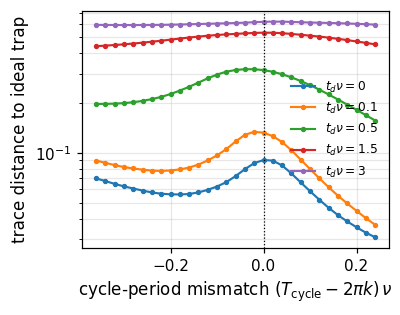

In [10]:
eta = 0.05
tau = tau_of(eta)
T_nom = t_cycle_new(eta, 1.0, None, 0.0)
k_res = round(T_nom / (2 * np.pi))
f_cal, d_cal = CAL[("ref", eta)]
print(f"nominal cycle: s = {T_nom - 2 * np.pi * k_res:+.4f}/nu (k = {k_res});  calibrated cycle: "
      f"s = {t_cycle_new(eta, f_cal, None, d_cal) - 2 * np.pi * k_res:+.4f}/nu")
S_GRID = np.round(np.arange(-0.36, 0.2401, 0.02), 4)
scan = {}
for delay in (0.0, 0.1, 0.5, 1.5, 3.0):
    tds = []
    for s in S_GRID:
        L = s - (T_nom - 2 * np.pi * k_res) - delay           # pulse lengthening that gives mismatch s
        tds.append(sim(dict(eta=eta, f=1 + L / tau, delay=delay)))
    scan[delay] = np.array(tds)
    i = int(np.argmax(scan[delay]))
    log(f"delay {delay:.1f}/nu: peak TD {scan[delay][i]:.3f} at s = {S_GRID[i]:+.2f}/nu")

fig, ax = plt.subplots(figsize=(3.6, 2.8))
for delay, tds in scan.items():
    ax.plot(S_GRID, tds, "o-", ms=2.5, label=rf"$t_d\nu={delay:g}$")
ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel(r"cycle-period mismatch $(T_{\rm cycle}-2\pi k)\,\nu$")
ax.set_ylabel("trace distance to ideal trap")
ax.set_yscale("log"); ax.grid(True, which="both", alpha=0.3)
ax.legend(frameon=False, fontsize=8)
fig.savefig(os.path.join(FIGDIR, "supp_cycle_resonance.pdf"))
show(fig); plt.close(fig)

**The bands of the Fig. 5(A) map.** This cell reads the cached map and computes the distance of every pixel from the resonance. Pixels within $0.1/\nu$ of it have a median error about two and a half times that of the rest: these are the bright bands at the lower left and upper right. The resonance is not the whole story, however. At the nominal pulse length, a delay of half a trap period gives $0.17$, more than the nominal $0.079$; the cell prints this value from the calibration grid.

In [11]:
FR, DL = FIG5_MAP_F_REL, FIG5_MAP_DELAYS
e = _r(FIG5_MAP_ETA)
specs = [dict(eta=e, f=_r(1 + e * fr), delay=_r(d), model="ref") for fr in FR for d in DL]
TD = np.array(run_sims("cal", specs, "map")).reshape(len(FR), len(DL)).T      # [delay, f]
Lgth = FR * e * tau_of(e)
s0 = T_nom - 2 * np.pi * round(T_nom / (2 * np.pi))
S = s0 + Lgth[None, :] + DL[:, None]                     # cycle-period mismatch of every pixel
dist = np.abs((S + np.pi) % (2 * np.pi) - np.pi)         # distance to the nearest resonance
for lo, hi in ((0, 0.1), (0.1, 0.2), (0.2, 0.4), (0.4, 0.8), (0.8, np.pi)):
    m = (dist >= lo) & (dist < hi)
    print(f"|T_cycle - 2 pi k| in [{lo:.1f}, {hi:.1f}): {m.sum():4d} pixels, median TD {np.median(TD[m]):.3f}, "
          f"max {TD[m].max():.3f}")
_grid = calibrate_many([0.05], "ref", "ref")[_r(0.05)]["grid"]
i0 = int(np.argmin(np.abs(CAL_F_REL)))
print(f"nominal pulse length: no delay {_grid[i0, 0]:.4f}, delay pi/nu (half a trap period) "
      f"{_grid[i0, int(np.argmin(np.abs(CAL_DELAYS - np.pi)))]:.4f}")

|T_cycle - 2 pi k| in [0.0, 0.1):   29 pixels, median TD 0.349, max 0.518


|T_cycle - 2 pi k| in [0.1, 0.2):   32 pixels, median TD 0.313, max 0.511


|T_cycle - 2 pi k| in [0.2, 0.4):   58 pixels, median TD 0.251, max 0.483


|T_cycle - 2 pi k| in [0.4, 0.8):  119 pixels, median TD 0.172, max 0.441


|T_cycle - 2 pi k| in [0.8, 3.1):  698 pixels, median TD 0.143, max 0.379


nominal pulse length: no delay 0.0789, delay pi/nu (half a trap period) 0.1682
